In [ ]:
import pandas as pd

df_api = pd.read_parquet("../data/processed/comtrade_code_5_base.parquet")
df_db  = pd.read_parquet("../data/processed/comtrade_441012_base.parquet")

In [2]:
df_api.shape, df_db.shape

((26097, 53), (25589, 61))

In [3]:
df_db[df_db['value_usd']<=0]["value_usd"].shape

(7,)

In [4]:
df_api[df_api['value_usd']<=0]["value_usd"].shape

(0,)

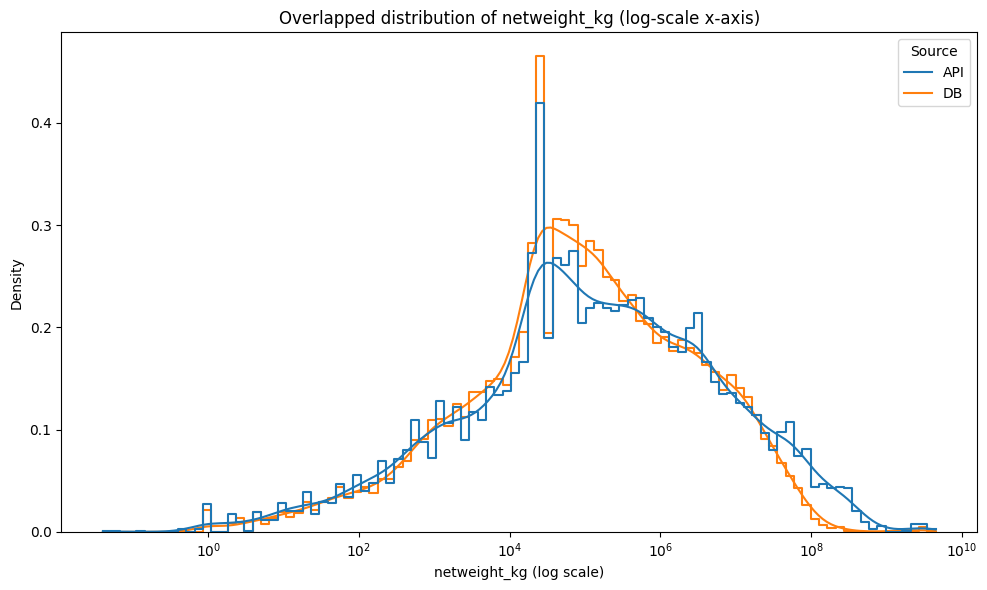

In [6]:
# Overlapped distribution of netweight_kg for API vs DB on log-scale x-axis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

column = "netweight_kg"
bins = 100

plot_df = pd.concat(
    [
        df_api[[column]].assign(source="API"),
        df_db[[column]].assign(source="DB"),
    ],
    ignore_index=True,
)

plot_df = plot_df.loc[
    plot_df[column].notna()
    & (plot_df[column] > 0)
].copy()

plt.figure(figsize=(10, 6))
ax = sns.histplot(
    data=plot_df,
    x=column,
    hue="source",
    bins=bins,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    kde=True,
    log_scale=(True, False),
)

plt.title(f"Overlapped distribution of {column} (log-scale x-axis)")
plt.xlabel(f"{column} (log scale)")
plt.ylabel("Density")

legend = ax.get_legend()
if legend is not None:
    legend.set_title("Source")

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_overlapped_distribution(
    df_left,
    df_right,
    column,
    left_label="API",
    right_label="DB",
    bins=100,
    figsize=(10, 6),
    min_positive=True,
    dropna=True,
    log_scale=True,
    kde=True,
):
    plot_df = pd.concat(
        [
            df_left[[column]].assign(source=left_label),
            df_right[[column]].assign(source=right_label),
        ],
        ignore_index=True,
    )

    mask = pd.Series(True, index=plot_df.index)

    if dropna:
        mask &= plot_df[column].notna()

    if min_positive:
        mask &= plot_df[column] > 0

    plot_df = plot_df.loc[mask].copy()

    plt.figure(figsize=figsize)
    ax = sns.histplot(
        data=plot_df,
        x=column,
        hue="source",
        bins=bins,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        kde=kde,
        log_scale=(log_scale, False),
    )

    scale_label = "log scale" if log_scale else "normal scale"
    plt.title(f"Overlapped distribution of {column} ({scale_label} x-axis)")
    plt.xlabel(f"{column} ({scale_label})")
    plt.ylabel("Density")

    legend = ax.get_legend()
    if legend is not None:
        legend.set_title("Source")

    plt.tight_layout()
    plt.show()

## Raw Data Comparison

In [24]:
### Read DB Data
df_db = pd.read_csv("../data/raw/Comtrade_441012.csv", delimiter=";")
print(df_db.shape)
df_db.head(4)
df_db.rename(columns={"CD_Netweight_kg": "netweight_kg"}, inplace=True)
df_db.rename(columns={"CD_Value": "value_usd"}, inplace=True)

(25589, 29)


In [29]:
df_db['CD_Year'].value_counts().sort_index()

CD_Year
2007    1308
2008    1430
2009    1380
2010    1415
2011    1516
2012    1603
2013    1634
2014    1613
2015    1719
2016    1782
2017    1804
2018    1854
2019    1877
2020    1798
2021    1935
2022     921
Name: count, dtype: int64

In [31]:
## Read Alternative 441012 Parquet Data from API
df_api_alt = pd.read_parquet("../data/raw/api/Comtrade_441012.parquet")
df_api_alt.shape

(18120, 47)

In [33]:
df_api_alt.head(2)

,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,primaryValue,legacyEstimationFlag,isReported,isAggregate
0,C,A,20070101,2007,52,2007,12,DZA,Algeria,M,...,3351214.0,False,NaN,False,1628491.000,NaN,1628491.000,0,True,False
1,C,A,20070101,2007,52,2007,20,AND,Andorra,M,...,24875.0,False,0.0,False,11119.992,NaN,11119.992,0,False,True


In [37]:
df_api_alt['cmdCode'].value_counts().sort_index()

cmdCode
441012    18120
Name: count, dtype: int64

In [ ]:
df_api_alt['refYear'].value_counts().sort_index()

In [19]:
## Read API data
df_api = pd.read_csv("../data/raw/api/Comtrade_hs_441012_trade.csv")
print(df_api.shape)
df_api.head(4)
df_api.rename(columns={"NetWgt": "netweight_kg"}, inplace=True)
df_api.rename(columns={"PrimaryValue": "value_usd"}, inplace=True)

(26097, 47)


In [27]:
df_api['RefYear'].value_counts().sort_index()

RefYear
2014    1157
2015    1374
2016    1642
2017    2246
2018    2146
2019    2446
2020    2422
2021    2697
2022    2918
2023    3006
2024    2589
2025    1454
Name: count, dtype: int64

In [20]:
df_api[['netweight_kg', 'value_usd']].head(4)

,netweight_kg,value_usd
0,151953.0,73102.0
1,735109.0,397168.0
2,291819.0,351573.0
3,196191.0,130391.0


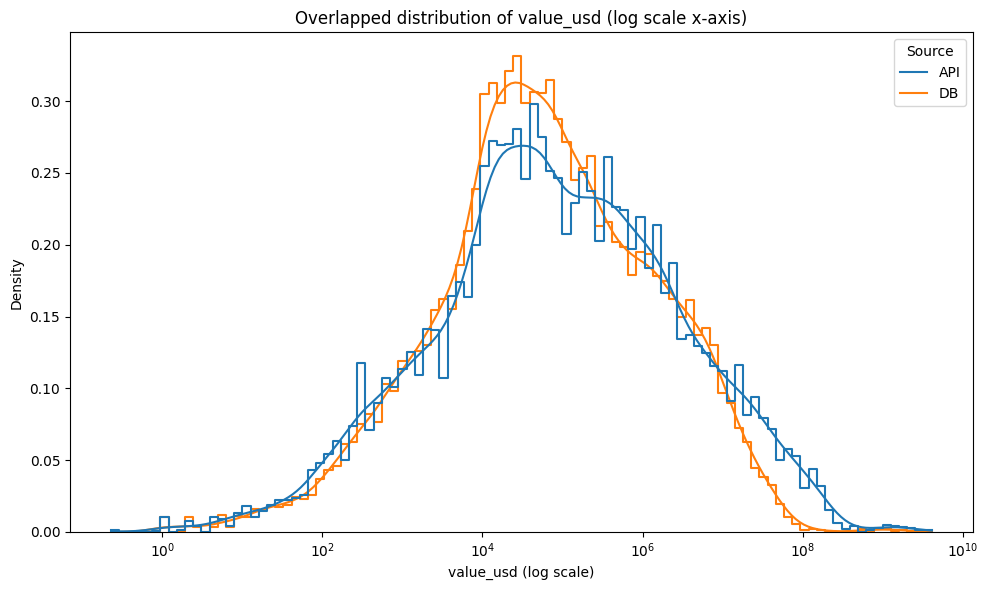

In [23]:
from vacoda.visualization.relationships import plot_overlapped_distribution
plot_overlapped_distribution(
    df_api,
    df_db,
    column="value_usd",
    left_label="API",
    right_label="DB",
    bins=100,
    log_scale=True,
)